NOTEBOOK 01 — IIT DELHI DATASET COLLECTION AND ANALYSIS
Dataset: /content/drive/MyDrive/Ocular_Project/datasets/IITD_database/IITD_database

1. DATASET INVENTORY
---------------------------------------------------------------------------
Total files: 3271
Image files: 3270
Other files: 1
Extensions: {'.bmp': 3270, '.txt': 1}

Dataset Readme preview:
Description of the IITD Iris Image Database version 1.0

This iris image database mainly consists of the iris images collected from the students and staff at IIT Delhi, India. This database has been acquired in
the Biometrics Research Laboratory during January - July 2007 using JIRIS, JPC1000, digital CMOS camera. The acquired images were saved in bitmap format.
The currently available database of 2180 images is acquired from 218 different users and made available freely to the researchers. All the subjects in the
database are in the age group 14-55 years comprising of 175 males and 43 females. The resolution of these images is 320 x 240 pi

eye,1,2,3,4,5,L,R
subject,,,,,,,
001,0,0,0,0,0,5,5
002,0,0,0,0,0,5,5
003,0,0,0,0,0,5,5
004,0,0,0,0,0,5,5
005,0,0,0,0,0,5,5
006,0,0,0,0,0,5,5
007,0,0,0,0,0,5,5
008,0,0,0,0,0,5,5
009,0,0,0,0,0,5,5



3. IMAGE VALIDATION AND DIMENSIONS
---------------------------------------------------------------------------
Validated 500/3270 images
Validated 1000/3270 images
Validated 1500/3270 images
Validated 2000/3270 images
Validated 2500/3270 images
Validated 3000/3270 images

Valid images: 3270
Invalid/unreadable images: 0
Validation time (seconds): 17.14

Image dimensions:


,width,height,mode,count
0,320,240,RGB,2180
1,432,48,L,1090



4. EXACT DUPLICATE CHECK
---------------------------------------------------------------------------
Unique file hashes: 3257
Exact duplicate groups: 13
Extra duplicate files: 13

5. BASIC IMAGE INTENSITY STATISTICS
---------------------------------------------------------------------------


,mean_brightness,intensity_std,min_intensity,max_intensity
count,3270.000,3270.000,3270.0,3270.0
mean,114.072,74.664,0.0,255.0
std,14.968,16.432,0.0,0.0
min,72.611,47.112,0.0,255.0
25%,103.056,61.750,0.0,255.0
50%,108.902,67.465,0.0,255.0
75%,124.470,96.022,0.0,255.0
max,164.234,100.853,0.0,255.0



6. RANDOM IMAGE SAMPLE
---------------------------------------------------------------------------


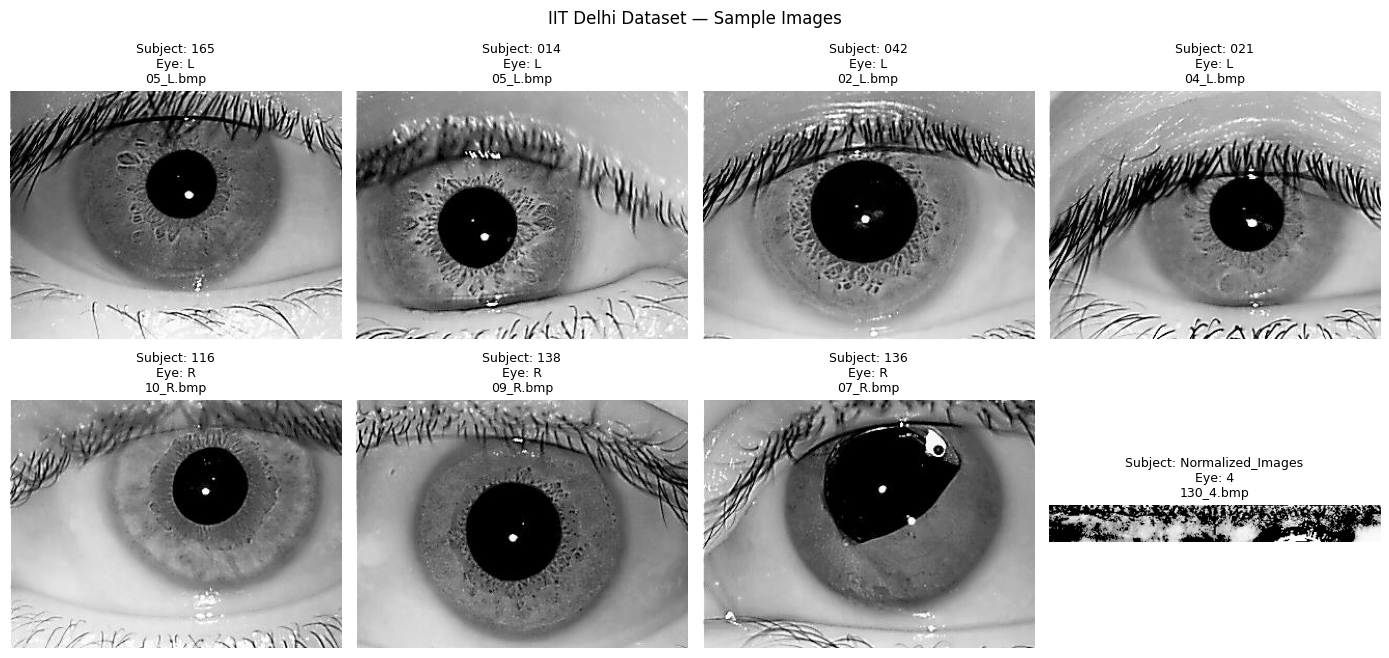

Sample visualization saved: /content/drive/MyDrive/Ocular_Project/results/IITD/notebook01_dataset_analysis/dataset_sample_images.png

NOTEBOOK 01 COMPLETE
{
  "dataset_name": "IIT Delhi Iris Database",
  "dataset_root": "/content/drive/MyDrive/Ocular_Project/datasets/IITD_database/IITD_database",
  "total_files": 3271,
  "image_count": 3270,
  "valid_image_count": 3270,
  "invalid_image_count": 0,
  "subject_folder_count": 219,
  "eye_label_counts": {
    "L": 1148,
    "R": 1032,
    "1": 218,
    "2": 218,
    "3": 218,
    "4": 218,
    "5": 218
  },
  "extension_counts": {
    ".bmp": 3270,
    ".txt": 1
  },
  "exact_duplicate_groups": 13,
  "extra_duplicate_files": 13,
  "dimension_counts": [
    {
      "width": 320,
      "height": 240,
      "count": 2180
    },
    {
      "width": 432,
      "height": 48,
      "count": 1090
    }
  ],
  "notes": [
    "Subject and eye labels were inferred from folder and filename structure.",
    "Read the dataset documentation before final

In [3]:

# ================================================================
# NOTEBOOK 01 — IIT DELHI DATASET COLLECTION AND ANALYSIS
# Single-cell end-to-end dataset audit
# ================================================================

from pathlib import Path
from collections import Counter
import hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = False

PROJECT = Path("/content/drive/MyDrive/Ocular_Project")
DATASET_ROOT = PROJECT / "datasets/IITD_database/IITD_database"
OUT = PROJECT / "results/IITD/notebook01_dataset_analysis"
OUT.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"}

assert DATASET_ROOT.exists(), f"Dataset folder not found: {DATASET_ROOT}"

print("=" * 75)
print("NOTEBOOK 01 — IIT DELHI DATASET COLLECTION AND ANALYSIS")
print("=" * 75)
print("Dataset:", DATASET_ROOT)

# 1. Discover files
all_files = sorted(p for p in DATASET_ROOT.rglob("*") if p.is_file())
image_paths = [p for p in all_files if p.suffix.lower() in IMAGE_EXTS]
non_image_files = [p for p in all_files if p.suffix.lower() not in IMAGE_EXTS]

print("\n1. DATASET INVENTORY")
print("-" * 75)
print("Total files:", len(all_files))
print("Image files:", len(image_paths))
print("Other files:", len(non_image_files))
print("Extensions:", dict(Counter(p.suffix.lower() for p in all_files)))

# Read documentation if present
readme_paths = [p for p in non_image_files if p.name.lower() == "readme.txt"]
for readme in readme_paths:
    print("\nDataset Readme preview:")
    try:
        print(readme.read_text(errors="replace")[:5000])
    except Exception as e:
        print("Could not read Readme:", e)

# 2. Build metadata from directory and filename
rows = []
for path in image_paths:
    # Expected pattern: subject_folder / 01_L.bmp
    subject = path.parent.name
    stem = path.stem
    eye = stem.rsplit("_", 1)[-1].upper() if "_" in stem else "unknown"
    capture = stem.rsplit("_", 1)[0] if "_" in stem else stem

    rows.append({
        "image_path": str(path),
        "relative_path": str(path.relative_to(DATASET_ROOT)),
        "filename": path.name,
        "subject": subject,
        "eye": eye,
        "capture_id": capture,
        "extension": path.suffix.lower()
    })

df = pd.DataFrame(rows)
if not df.empty:
    df = df.sort_values(["subject", "eye", "filename"]).reset_index(drop=True)

print("\n2. SUBJECT AND EYE DISTRIBUTION")
print("-" * 75)
print("Unique subject folders:", df["subject"].nunique() if len(df) else 0)
print("\nImages per subject:")
print(df.groupby("subject").size().describe() if len(df) else "No images found")

print("\nEye label counts:")
print(df["eye"].value_counts(dropna=False) if len(df) else "No images found")

subject_eye_counts = (
    df.groupby(["subject", "eye"]).size().unstack(fill_value=0)
    if len(df) else pd.DataFrame()
)
print("\nImages per subject by eye (first 15 subjects):")
display(subject_eye_counts.head(15))

# 3. Validate files and record image properties
print("\n3. IMAGE VALIDATION AND DIMENSIONS")
print("-" * 75)
valid_rows, errors = [], []
start = time.time()

for i, row in df.iterrows():
    path = Path(row["image_path"])
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            width, height = im.size
            mode = im.mode
            fmt = im.format

        valid_rows.append({
            "image_path": str(path),
            "valid_image": True,
            "width": width,
            "height": height,
            "mode": mode,
            "format": fmt,
            "file_size_bytes": path.stat().st_size
        })
    except Exception as e:
        errors.append({
            "image_path": str(path),
            "error": str(e)
        })
        valid_rows.append({
            "image_path": str(path),
            "valid_image": False,
            "width": None,
            "height": None,
            "mode": None,
            "format": None,
            "file_size_bytes": path.stat().st_size if path.exists() else None
        })

    if (i + 1) % 500 == 0:
        print(f"Validated {i+1}/{len(df)} images")

validation_df = pd.DataFrame(valid_rows)
df = df.merge(validation_df, on="image_path", how="left")

valid_df = df[df["valid_image"] == True].copy()
invalid_df = df[df["valid_image"] != True].copy()

print("\nValid images:", len(valid_df))
print("Invalid/unreadable images:", len(invalid_df))
print("Validation time (seconds):", round(time.time() - start, 2))
print("\nImage dimensions:")
display(
    valid_df.groupby(["width", "height", "mode"]).size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(20)
)

# 4. Duplicate detection using file hashes
print("\n4. EXACT DUPLICATE CHECK")
print("-" * 75)
hash_to_paths = {}
for i, path in enumerate(image_paths, 1):
    try:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(str(path))
    except Exception as e:
        errors.append({"image_path": str(path), "error": f"Hash error: {e}"})

duplicate_groups = [
    paths for paths in hash_to_paths.values() if len(paths) > 1
]
duplicate_file_count = sum(len(g) - 1 for g in duplicate_groups)

print("Unique file hashes:", len(hash_to_paths))
print("Exact duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_file_count)

# 5. Image quality statistics
print("\n5. BASIC IMAGE INTENSITY STATISTICS")
print("-" * 75)
quality_rows = []

for i, row in valid_df.iterrows():
    try:
        with Image.open(row["image_path"]) as im:
            gray = np.asarray(im.convert("L"), dtype=np.float32)

        quality_rows.append({
            "image_path": row["image_path"],
            "subject": row["subject"],
            "eye": row["eye"],
            "mean_brightness": float(gray.mean()),
            "intensity_std": float(gray.std()),
            "min_intensity": int(gray.min()),
            "max_intensity": int(gray.max())
        })
    except Exception as e:
        errors.append({
            "image_path": row["image_path"],
            "error": f"Quality calculation error: {e}"
        })

quality_df = pd.DataFrame(quality_rows)
if len(quality_df):
    display(quality_df[
        ["mean_brightness", "intensity_std", "min_intensity", "max_intensity"]
    ].describe().round(3))

# 6. Visualize a small sample
print("\n6. RANDOM IMAGE SAMPLE")
print("-" * 75)

if len(valid_df):
    sample_n = min(8, len(valid_df))
    sample_df = valid_df.sample(sample_n, random_state=42)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        with Image.open(row["image_path"]) as im:
            ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(
            f"Subject: {row['subject']}\nEye: {row['eye']}\n{row['filename']}",
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle("IIT Delhi Dataset — Sample Images")
    plt.tight_layout()
    sample_plot = OUT / "dataset_sample_images.png"
    plt.savefig(sample_plot, dpi=160, bbox_inches="tight")
    plt.show()
    print("Sample visualization saved:", sample_plot)

# 7. Save reusable metadata and reports
metadata_csv = OUT / "IITD_dataset_metadata.csv"
subject_csv = OUT / "IITD_subject_eye_distribution.csv"
quality_csv = OUT / "IITD_basic_image_statistics.csv"
invalid_csv = OUT / "IITD_invalid_images.csv"
duplicates_json = OUT / "IITD_exact_duplicates.json"
report_json = OUT / "IITD_dataset_analysis_summary.json"

df.to_csv(metadata_csv, index=False)
subject_eye_counts.to_csv(subject_csv)
quality_df.to_csv(quality_csv, index=False)
invalid_df.to_csv(invalid_csv, index=False)

with open(duplicates_json, "w") as f:
    json.dump(duplicate_groups, f, indent=2)

summary = {
    "dataset_name": "IIT Delhi Iris Database",
    "dataset_root": str(DATASET_ROOT),
    "total_files": len(all_files),
    "image_count": len(image_paths),
    "valid_image_count": len(valid_df),
    "invalid_image_count": len(invalid_df),
    "subject_folder_count": int(df["subject"].nunique()) if len(df) else 0,
    "eye_label_counts": {
        str(k): int(v) for k, v in df["eye"].value_counts().items()
    } if len(df) else {},
    "extension_counts": dict(Counter(p.suffix.lower() for p in all_files)),
    "exact_duplicate_groups": len(duplicate_groups),
    "extra_duplicate_files": int(duplicate_file_count),
    "dimension_counts": (
        valid_df.groupby(["width", "height"]).size()
        .reset_index(name="count")
        .to_dict(orient="records")
        if len(valid_df) else []
    ),
    "notes": [
        "Subject and eye labels were inferred from folder and filename structure.",
        "Read the dataset documentation before finalizing the interpretation of labels.",
        "This notebook does not create train/validation/test splits or train a model."
    ]
}

with open(report_json, "w") as f:
    json.dump(summary, f, indent=2)

if errors:
    pd.DataFrame(errors).to_csv(OUT / "IITD_processing_errors.csv", index=False)

print("\n" + "=" * 75)
print("NOTEBOOK 01 COMPLETE")
print("=" * 75)
print(json.dumps(summary, indent=2))
print("\nSaved outputs:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f" - {p.name} ({p.stat().st_size / 1024:.1f} KB)")

print("\nNext: inspect these results and the Readme before defining the dataset split.")
